# Notebook 02: Exact Brute-Force (Flat) Search & Baseline Benchmarking

Welcome to the second notebook in the **Vector Search & Indexing from Scratch** series!

In [Notebook 01](01_vector_space_metrics_and_topk.ipynb), we explored the geometry of vector spaces, the mathematics of similarity metrics (Euclidean, Manhattan, Dot Product, Cosine), and Top-K selection heuristics.

Now, we take those foundational pieces and assemble them into a complete retrieval system: **The Exact Brute-Force Search Engine** (commonly known in production as a **Flat Index**).

---

### Why Master Brute-Force Before Approximate Search (ANN)?

In modern vector databases (like Faiss, Milvus, Qdrant, and Pinecone), engineers are often tempted to jump directly to complex Approximate Nearest Neighbor (ANN) graphs like HNSW or inverted indexes like IVF. 

However, **Exact Brute-Force Search is the most vital benchmark in the entire discipline**:
1. **The Ground Truth Standard**: Approximate algorithms trade accuracy for speed. But how do you know if an ANN index retrieved the *right* vectors? You must compare its results against the **100% exact Ground Truth** produced by Brute-Force search.
2. **The "Surprising Sweet Spot"**: For datasets under $50,000$ to $100,000$ vectors (common in enterprise multi-tenant RAG, user-isolated workspaces, and legal document search), Brute-Force is often **faster to build, requires zero hyperparameter tuning, uses less memory, and guarantees 100% recall**.
3. **Hardware Acceleration**: When implemented using vectorized Basic Linear Algebra Subprograms (BLAS `GEMM`), exact search runs at peak CPU/GPU hardware FLOP rates.

```
                    Exact Brute-Force Search (Flat Index)
                                  │
         ┌────────────────────────┴────────────────────────┐
         ▼                                                 ▼
   Strengths:                                        Limitations:
   • 100% Recall (Zero False Negatives)              • Latency scales linearly: O(N)
   • 0 ms Index Build Time                           • RAM usage scales linearly: O(N × d)
   • Trivial Insertions & Deletions                  • Hits the "Memory Bandwidth Wall"
   • Ground Truth for all ANN algorithms               at scale (> 1M vectors)
```

---

### Learning Objectives in this Notebook:
1. **Matrix Formulation of Vector Search**: Formulate batch search as a single matrix multiplication ($Q \cdot X^T$) rather than iterative loops.
2. **The Vectorized Euclidean Distance Expansion Trick**: Compute all pairwise $L_2$ distances without allocating huge $(B \times N \times d)$ 3D tensors.
3. **Memory Footprint & The Hardware Wall**: Calculate RAM requirements across vector dimensions ($d=384, 768, 1536$) and uncover why memory bandwidth caps exact search speed.
4. **Building `ExactFlatIndex` from Scratch**: An object-oriented, production-ready flat index supporting Cosine, Inner Product, and Euclidean metrics with batch querying.
5. **Empirical Benchmarking**: Measure search latency, Queries Per Second (QPS), and scaling bottlenecks across dataset sizes up to $500,000$ vectors.
6. **Generating the "Ground Truth" Testbed**: Create a standardized benchmark dataset and ground-truth index to evaluate Recall@K in upcoming notebooks.
7. **Industry Reference Comparison**: Compare our scratch index against `faiss.IndexFlatL2` and `faiss.IndexFlatIP`.
8. **Pros, Cons & Decision Rules**: When to choose Brute-Force over ANN in production RAG systems.


---
## 1. Setup & Environment

Let's import our scientific computing stack. We will use NumPy for from-scratch matrix operations and Matplotlib for performance scaling visualizations.


In [1]:
import sys
import time
from typing import List, Tuple, Dict, Any, Optional

import numpy as np
import matplotlib.pyplot as plt

# Ensure reproducible random distributions
np.random.seed(42)

print(f"Python version: {sys.version.split()[0]}")
print(f"NumPy version:  {np.__version__}")
print("Ready to build Exact Vector Search!")


Python version: 3.13.16
NumPy version:  2.1.3
Ready to build Exact Vector Search!


---
## 2. Mathematical Formulation: From Loops to BLAS

Suppose our corpus contains $N$ document chunks, each represented by a dense embedding vector of dimension $d$. We organize the entire database into a 2D matrix:
$$\mathbf{X} \in \mathbb{R}^{N \times d}$$

Now, suppose a batch of $B$ user queries arrives simultaneously (or a single query where $B=1$):
$$\mathbf{Q} \in \mathbb{R}^{B \times d}$$

### 2.1 The Naive Nested Loop Approach: $O(B \cdot N \cdot d)$
If we loop over each query $b \in [0, B-1]$ and each document $i \in [0, N-1]$ in Python:
```python
for q in queries:
    for doc in documents:
        score = dot_product(q, doc)
```
In Python, looping over $N = 1,000,000$ vectors takes **seconds per query** due to interpreter overhead and cache misses.

---

### 2.2 The Matrix Multiplication Formulation (Inner Product / Cosine)
Instead of scalar loops, the similarity between all $B$ queries and all $N$ documents is computed in **one single matrix multiplication**:

$$\mathbf{S} = \mathbf{Q} \cdot \mathbf{X}^T$$

Where:
- $\mathbf{Q} \in \mathbb{R}^{B \times d}$
- $\mathbf{X}^T \in \mathbb{R}^{d \times N}$
- $\mathbf{S} \in \mathbb{R}^{B \times N}$, where cell $S_{b, i} = \mathbf{q}_b \cdot \mathbf{x}_i$ is the exact inner product between query $b$ and document $i$.

Under the hood, NumPy delegates this to hardware-optimized BLAS libraries (Intel MKL, OpenBLAS, or Apple Accelerate) using vectorized SIMD instructions (AVX-512, AVX2, NEON), utilizing all CPU cores and vector registers.

---

### 2.3 The Vectorized Euclidean Distance Expansion Trick
How do we compute pairwise Euclidean distances between $B$ queries and $N$ documents without looping?

A naive vectorized approach might compute differences:
```python
diff = Q[:, np.newaxis, :] - X[np.newaxis, :, :]  # Shape: (B, N, d)
```
> **Warning**: For $B=100$, $N=100,000$, and $d=768$, the 3D tensor `diff` would require:
> $$100 \times 100,000 \times 768 \times 4 \text{ bytes} \approx 30.72 \text{ GB of RAM!}$$
> This will instantly crash your system with an `OutOfMemoryError`.

#### The Algebraic Expansion Solution:
Recall the expansion of squared Euclidean distance:
$$\|\mathbf{q} - \mathbf{x}_i\|_2^2 = \|\mathbf{q}\|_2^2 + \|\mathbf{x}_i\|_2^2 - 2 (\mathbf{q} \cdot \mathbf{x}_i)$$

In matrix form:
$$\mathbf{D}^2 = \mathbf{n}_Q + \mathbf{n}_X^T - 2 (\mathbf{Q} \mathbf{X}^T)$$

Where:
- $\mathbf{n}_Q = \sum_{j=1}^d Q_{b, j}^2 \in \mathbb{R}^{B \times 1}$ (squared norms of queries)
- $\mathbf{n}_X^T = \sum_{j=1}^d X_{i, j}^2 \in \mathbb{R}^{1 \times N}$ (squared norms of documents)
- $\mathbf{Q} \mathbf{X}^T \in \mathbb{R}^{B \times N}$ (computed via fast BLAS `gemm`)

This requires **zero 3D memory allocation** and runs up to $50\times$ faster! Let's implement and verify both!


In [2]:
def batch_inner_product(Q: np.ndarray, X: np.ndarray) -> np.ndarray:
    """Compute all pairwise inner products between queries Q and documents X.
    
    Args:
        Q: Queries matrix of shape (B, d)
        X: Corpus matrix of shape (N, d)
    Returns:
        Scores matrix S of shape (B, N)
    """
    return np.matmul(Q, X.T)  # or Q @ X.T


def batch_squared_euclidean(Q: np.ndarray, X: np.ndarray) -> np.ndarray:
    """Compute all pairwise squared Euclidean distances using algebraic expansion.
    
    Formula: ||Q - X||^2 = ||Q||^2 + ||X||^2 - 2 * (Q @ X.T)
    Memory: O(B * N) instead of O(B * N * d)
    """
    # 1. Squared norms of queries: shape (B, 1)
    q_sq_norms = np.sum(Q ** 2, axis=1, keepdims=True)
    
    # 2. Squared norms of documents: shape (1, N)
    x_sq_norms = np.sum(X ** 2, axis=1, keepdims=True).T
    
    # 3. Dot product matrix: shape (B, N)
    dot_matrix = np.matmul(Q, X.T)
    
    # 4. Combine via NumPy broadcasting: (B, 1) + (1, N) - 2 * (B, N)
    dists_sq = q_sq_norms + x_sq_norms - 2.0 * dot_matrix
    
    # Numerical safeguard: floating point inaccuracies can yield tiny negative numbers (e.g. -1e-7)
    return np.maximum(dists_sq, 0.0)


# Let's verify numerical correctness on a small test batch
B_test, N_test, d_test = 5, 20, 16
Q_test = np.random.randn(B_test, d_test).astype(np.float32)
X_test = np.random.randn(N_test, d_test).astype(np.float32)

# Check our matrix inner product
S_test = batch_inner_product(Q_test, X_test)
for b in range(B_test):
    for i in range(N_test):
        expected_dot = float(np.dot(Q_test[b], X_test[i]))
        assert np.isclose(S_test[b, i], expected_dot, atol=1e-5), "Inner product mismatch!"

# Check our expansion squared L2 against naive loop
D2_test = batch_squared_euclidean(Q_test, X_test)
for b in range(B_test):
    for i in range(N_test):
        diff = Q_test[b] - X_test[i]
        expected_l2_sq = float(np.dot(diff, diff))
        assert np.isclose(D2_test[b, i], expected_l2_sq, atol=1e-4), "L2 squared mismatch!"

print(" Mathematical Formulations Verified:")
print(f"  Inner Product Matrix Shape:      {S_test.shape} (B x N)")
print(f"  Squared Euclidean Matrix Shape: {D2_test.shape} (B x N)")
print("  All values match naive mathematical definitions within machine precision!")


 Mathematical Formulations Verified:
  Inner Product Matrix Shape:      (5, 20) (B x N)
  Squared Euclidean Matrix Shape: (5, 20) (B x N)
  All values match naive mathematical definitions within machine precision!


---
## 3. Memory Footprint & The Hardware Wall

Before building the full index, every system architect must answer:
> **How much RAM does an exact flat index require, and when does it hit the hardware limits?**

### The Memory Equation:
Each coordinate in a standard dense vector is stored as a 32-bit single-precision float (`float32`), which occupies **4 bytes**:

$$\text{RAM (Bytes)} = N \times d \times 4 \text{ bytes}$$

$$\text{RAM (Megabytes)} = \frac{N \times d \times 4}{1024^2}$$

$$\text{RAM (Gigabytes)} = \frac{N \times d \times 4}{1024^3}$$

Let's calculate the exact memory requirements across standard industry models:
- Small embeddings ($d=384$): MiniLM, BGE-small
- Standard embeddings ($d=768$): BGE-base, BERT, Nomic
- Large embeddings ($d=1536$): OpenAI `text-embedding-3-small`, `ada-002`
- Frontier embeddings ($d=3072$): OpenAI `text-embedding-3-large`


In [3]:
def calculate_memory_mb(num_vectors: int, dim: int) -> float:
    """Calculate raw vector memory footprint in Megabytes (float32)."""
    return (num_vectors * dim * 4) / (1024 ** 2)

corpus_sizes = [10_000, 100_000, 500_000, 1_000_000, 10_000_000]
dimensions = [384, 768, 1536, 3072]

print(f"{'Corpus Size (N)':<18} | " + " | ".join([f"d={dim} (MB)" for dim in dimensions]))
print("-" * 75)
for n in corpus_sizes:
    row_str = f"{n:<18,d} | "
    row_str += " | ".join([f"{calculate_memory_mb(n, dim):>10.1f}" for dim in dimensions])
    print(row_str)


Corpus Size (N)    | d=384 (MB) | d=768 (MB) | d=1536 (MB) | d=3072 (MB)
---------------------------------------------------------------------------
10,000             |       14.6 |       29.3 |       58.6 |      117.2
100,000            |      146.5 |      293.0 |      585.9 |     1171.9
500,000            |      732.4 |     1464.8 |     2929.7 |     5859.4
1,000,000          |     1464.8 |     2929.7 |     5859.4 |    11718.8
10,000,000         |    14648.4 |    29296.9 |    58593.8 |   117187.5


### The "Memory Bandwidth Wall" Explained

Why does Brute-Force search eventually slow down, even on powerful modern hardware?

Consider searching a database of **$1,000,000$ vectors** with $d = 768$:
- **Dataset Size**: $1,000,000 \times 768 \times 4 \text{ bytes} \approx 3.072 \text{ GB}$.
- For **every single query**, an exact search engine **must read all 3.072 GB of data from system RAM into CPU cache**.
- A high-end desktop CPU (DDR5-5600) has a maximum memory bandwidth of $\approx 60 \text{ GB/sec}$.
- **Theoretical Minimum Latency**:
  $$\text{Latency} \ge \frac{3.072 \text{ GB}}{60 \text{ GB/s}} \approx 0.0512 \text{ seconds} = 51.2 \text{ ms}$$

> **Key Architectural Insight**: Brute-Force search on large datasets is not compute-bound—it is **Memory-Bandwidth Bound**. Even if your CPU has 64 cores, the processor cores will sit idle waiting for RAM to deliver bytes across the memory bus!
>
> This fundamental physical constraint is the exact reason why **Product Quantization (PQ)** and **Approximate Nearest Neighbor (ANN)** algorithms were invented!


---
## 4. Building `ExactFlatIndex` From Scratch

Let's now implement a clean, robust, object-oriented flat vector index.

### Features of our `ExactFlatIndex`:
1. **Multiple Metrics**: Supports `'cosine'`, `'inner_product'` (MIPS), and `'euclidean'` ($L_2$).
2. **Offline Pre-Normalization**: If initialized with `'cosine'`, document vectors are automatically $L_2$-normalized upon ingestion so searches run via fast BLAS inner products!
3. **Dynamic Ingestion**: Supports adding documents incrementally (`add()`).
4. **Batched & Single Queries**: Accepts a single vector $(d,)$ or a batch matrix $(B, d)$.
5. **Fast Top-K Selection**: Employs `np.argpartition` ($O(N)$ introselect) combined with a final sort on just the $K$ returned candidates.
6. **Metadata / ID Mapping**: Maintains document ID associations.


In [4]:
class ExactFlatIndex:
    """Exact Brute-Force (Flat) Vector Search Index implemented from scratch.
    
    Guarantees 100% precision and 100% recall (Ground Truth).
    """
    
    VALID_METRICS = {"cosine", "inner_product", "euclidean"}
    
    def __init__(self, dim: int, metric: str = "cosine"):
        """Initialize Flat Index.
        
        Args:
            dim: Dimensionality of vector space (d)
            metric: Similarity/distance metric ('cosine', 'inner_product', or 'euclidean')
        """
        if metric not in self.VALID_METRICS:
            raise ValueError(f"Unsupported metric '{metric}'. Must be one of {self.VALID_METRICS}")
            
        self.dim = dim
        self.metric = metric
        
        # Internal contiguous storage for vectors: shape (N, d)
        self.vectors: Optional[np.ndarray] = None
        self.doc_ids: List[Any] = []
        self.total_vectors: int = 0
        
    def _normalize(self, x: np.ndarray) -> np.ndarray:
        """Project vectors onto unit hypersphere (L2 normalization)."""
        norms = np.linalg.norm(x, axis=-1, keepdims=True)
        # Avoid division by zero with small epsilon
        norms = np.maximum(norms, 1e-12)
        return x / norms
        
    def add(self, vectors: np.ndarray, ids: Optional[List[Any]] = None):
        """Ingest a batch of vectors into the index.
        
        Args:
            vectors: 2D array of shape (num_docs, dim)
            ids: Optional list of unique document identifiers
        """
        vectors = np.ascontiguousarray(vectors, dtype=np.float32)
        
        if vectors.ndim != 2 or vectors.shape[1] != self.dim:
            raise ValueError(f"Expected vectors of shape (N, {self.dim}), got {vectors.shape}")
            
        num_new = vectors.shape[0]
        
        # Default sequential integer IDs if not provided
        if ids is None:
            new_ids = list(range(self.total_vectors, self.total_vectors + num_new))
        else:
            if len(ids) != num_new:
                raise ValueError("Length of ids list must match number of vectors added")
            new_ids = list(ids)
            
        # If metric is cosine, pre-normalize vectors offline during ingestion
        if self.metric == "cosine":
            vectors = self._normalize(vectors)
            
        # Append or initialize internal matrix
        if self.vectors is None:
            self.vectors = vectors
        else:
            self.vectors = np.vstack([self.vectors, vectors])
            
        self.doc_ids.extend(new_ids)
        self.total_vectors += num_new
        
    def search(
        self, 
        queries: np.ndarray, 
        k: int = 10
    ) -> Tuple[np.ndarray, np.ndarray]:
        """Search for top-k nearest neighbors for a batch of queries.
        
        Args:
            queries: 1D array of shape (d,) or 2D array of shape (B, d)
            k: Number of nearest neighbors to retrieve
        Returns:
            Tuple of:
              - top_indices: (B, k) array of document IDs
              - top_scores:  (B, k) array of similarity scores or distances
        """
        if self.total_vectors == 0:
            raise RuntimeError("Cannot search an empty index!")
            
        k = min(k, self.total_vectors)
        
        # Ensure 2D query shape (B, d)
        queries = np.ascontiguousarray(queries, dtype=np.float32)
        single_query = (queries.ndim == 1)
        if single_query:
            queries = queries[np.newaxis, :]
            
        if queries.shape[1] != self.dim:
            raise ValueError(f"Query dimension {queries.shape[1]} does not match index dim {self.dim}")
            
        B = queries.shape[0]
        
        # ---------------------------------------------------------
        # Step 1: Compute full distance / similarity score matrix
        # ---------------------------------------------------------
        if self.metric in ("cosine", "inner_product"):
            if self.metric == "cosine":
                queries = self._normalize(queries)
            # Fast BLAS GEMM: (B, d) @ (d, N) -> (B, N)
            scores = np.matmul(queries, self.vectors.T)
            largest = True  # We want the HIGHEST similarity scores
            
        elif self.metric == "euclidean":
            # Vectorized squared L2 expansion: (B, N)
            q_norms_sq = np.sum(queries ** 2, axis=1, keepdims=True)
            doc_norms_sq = np.sum(self.vectors ** 2, axis=1, keepdims=True).T
            dot = np.matmul(queries, self.vectors.T)
            scores = np.maximum(q_norms_sq + doc_norms_sq - 2.0 * dot, 0.0)
            largest = False  # We want the LOWEST distances
            
        # ---------------------------------------------------------
        # Step 2: Efficient Top-K Selection via argpartition
        # ---------------------------------------------------------
        # argpartition is O(N) average time vs O(N log N) full sort
        if largest:
            # We want k largest: partition around N - k
            part_idx = np.argpartition(-scores, k, axis=1)[:, :k]
        else:
            # We want k smallest
            part_idx = np.argpartition(scores, k, axis=1)[:, :k]
            
        # Extract partitioned scores: shape (B, k)
        row_indices = np.arange(B)[:, np.newaxis]
        part_scores = scores[row_indices, part_idx]
        
        # Final sort on only the k candidates: O(k log k)
        if largest:
            sort_order = np.argsort(-part_scores, axis=1)
        else:
            sort_order = np.argsort(part_scores, axis=1)
            
        final_top_k_indices = np.take_along_axis(part_idx, sort_order, axis=1)
        final_top_k_scores = np.take_along_axis(part_scores, sort_order, axis=1)
        
        # Map internal array row indices to external document IDs
        doc_id_array = np.array(self.doc_ids)
        result_doc_ids = doc_id_array[final_top_k_indices]
        
        # Return exact Euclidean distance (apply sqrt) if metric is euclidean
        if self.metric == "euclidean":
            final_top_k_scores = np.sqrt(final_top_k_scores)
            
        if single_query:
            return result_doc_ids[0], final_top_k_scores[0]
            
        return result_doc_ids, final_top_k_scores


### Testing `ExactFlatIndex` on a Toy Semantic Dataset

Let's test our index with a toy semantic scenario: 5 document chunks and 1 query vector.


In [5]:
# Initialize index with d=4 and cosine metric
flat_idx = ExactFlatIndex(dim=4, metric="cosine")

# Synthetic documents with text identifiers
doc_embeddings = np.array([
    [1.0, 0.0, 0.0, 0.0],   # Doc 0: Pure dimension 0
    [0.0, 1.0, 0.0, 0.0],   # Doc 1: Pure dimension 1
    [0.7, 0.7, 0.0, 0.0],   # Doc 2: 45-degree blend of 0 & 1
    [0.9, 0.1, 0.0, 0.0],   # Doc 3: Closest to dimension 0
    [-1.0, 0.0, 0.0, 0.0],  # Doc 4: Opposite of dimension 0
], dtype=np.float32)

custom_ids = ["doc_apple", "doc_banana", "doc_fruit_blend", "doc_red_apple", "doc_anti_apple"]
flat_idx.add(doc_embeddings, ids=custom_ids)

# Query vector: heavily aligned with dimension 0
test_query = np.array([0.95, 0.05, 0.0, 0.0], dtype=np.float32)

# Retrieve top 3
top_ids, top_scores = flat_idx.search(test_query, k=3)

print("Query Results for 'test_query':")
for rank, (d_id, score) in enumerate(zip(top_ids, top_scores), 1):
    print(f"  Rank {rank}: {d_id:<16} | Cosine Similarity: {score:.4f}")

# Verification assertions
assert top_ids[0] in ("doc_apple", "doc_red_apple"), "Top document should be apple-related!"
assert "doc_anti_apple" not in top_ids, "Anti-apple should not be in top 3!"
print("\n ExactFlatIndex tests passed successfully!")


Query Results for 'test_query':
  Rank 1: doc_apple        | Cosine Similarity: 0.9986
  Rank 2: doc_red_apple    | Cosine Similarity: 0.9983
  Rank 3: doc_fruit_blend  | Cosine Similarity: 0.7433

 ExactFlatIndex tests passed successfully!


---
## 5. Empirical Scaling Analysis

To understand why vector search algorithms evolved into Approximate Nearest Neighbors (ANN), we must observe the limits of exact search firsthand.

Let's benchmark:
1. **Search Latency vs. Database Size ($N$)**: From $1,000$ to $500,000$ vectors ($d=128$).
2. **Throughput (QPS - Queries Per Second) vs. Batch Size ($B$)**: Testing $B=1, 10, 50, 100$ to observe BLAS parallel efficiency.


In [6]:
dim_bench = 128
test_sizes = [1_000, 10_000, 50_000, 100_000, 250_000, 500_000]
k_bench = 10

latencies_single_query_ms = []

print("Running Scaling Benchmark (Single Query, d=128)...")
print(f"{'Corpus Size (N)':<18} | {'Latency (ms)':<15} | {'Throughput (QPS)':<18}")
print("-" * 55)

for n_size in test_sizes:
    # Create index
    idx = ExactFlatIndex(dim=dim_bench, metric="cosine")
    
    # Generate random corpus and query
    corpus_sample = np.random.randn(n_size, dim_bench).astype(np.float32)
    query_sample = np.random.randn(dim_bench).astype(np.float32)
    
    idx.add(corpus_sample)
    
    # Warmup
    _ = idx.search(query_sample, k=k_bench)
    
    # Timed runs
    num_trials = 5 if n_size <= 100_000 else 3
    t_start = time.perf_counter()
    for _ in range(num_trials):
        _ = idx.search(query_sample, k=k_bench)
    t_avg_ms = ((time.perf_counter() - t_start) / num_trials) * 1000.0
    qps = 1000.0 / t_avg_ms
    
    latencies_single_query_ms.append(t_avg_ms)
    print(f"{n_size:<18,d} | {t_avg_ms:<15.2f} | {qps:<18.1f}")


Running Scaling Benchmark (Single Query, d=128)...
Corpus Size (N)    | Latency (ms)    | Throughput (QPS)  
-------------------------------------------------------
1,000              | 0.32            | 3088.1            
10,000             | 1.94            | 516.2             
50,000             | 8.88            | 112.6             
100,000            | 20.18           | 49.6              
250,000            | 44.42           | 22.5              
500,000            | 88.56           | 11.3              


### 5.2 Batch Query Efficiency: The Power of BLAS Vectorization
When multiple queries are batched together, matrix operations make much better use of CPU cache and SIMD pipelines.


In [7]:
# Benchmark batch sizes on N=100,000 vectors
batch_sizes = [1, 5, 20, 50, 100]
N_fixed = 100_000

idx_batch = ExactFlatIndex(dim=dim_bench, metric="cosine")
idx_batch.add(np.random.randn(N_fixed, dim_bench).astype(np.float32))

batch_qps_results = []
batch_latencies_ms = []

print(f"\nBatch Search Scaling on N={N_fixed:,d} vectors:")
print(f"{'Batch Size (B)':<16} | {'Total Latency (ms)':<20} | {'Throughput (QPS)':<18}")
print("-" * 58)

for b_size in batch_sizes:
    queries_batch = np.random.randn(b_size, dim_bench).astype(np.float32)
    
    # Warmup
    _ = idx_batch.search(queries_batch, k=k_bench)
    
    trials = 3
    t0 = time.perf_counter()
    for _ in range(trials):
        _ = idx_batch.search(queries_batch, k=k_bench)
    total_time_ms = ((time.perf_counter() - t0) / trials) * 1000.0
    
    # QPS = total queries evaluated per second
    effective_qps = (b_size / (total_time_ms / 1000.0))
    batch_qps_results.append(effective_qps)
    batch_latencies_ms.append(total_time_ms)
    
    print(f"{b_size:<16} | {total_time_ms:<20.2f} | {effective_qps:<18.1f}")



Batch Search Scaling on N=100,000 vectors:
Batch Size (B)   | Total Latency (ms)   | Throughput (QPS)  
----------------------------------------------------------
1                | 32.39                | 30.9              
5                | 63.88                | 78.3              
20               | 103.86               | 192.6             
50               | 113.70               | 439.8             
100              | 206.41               | 484.5             


### Visualizing Exact Search Scaling Laws


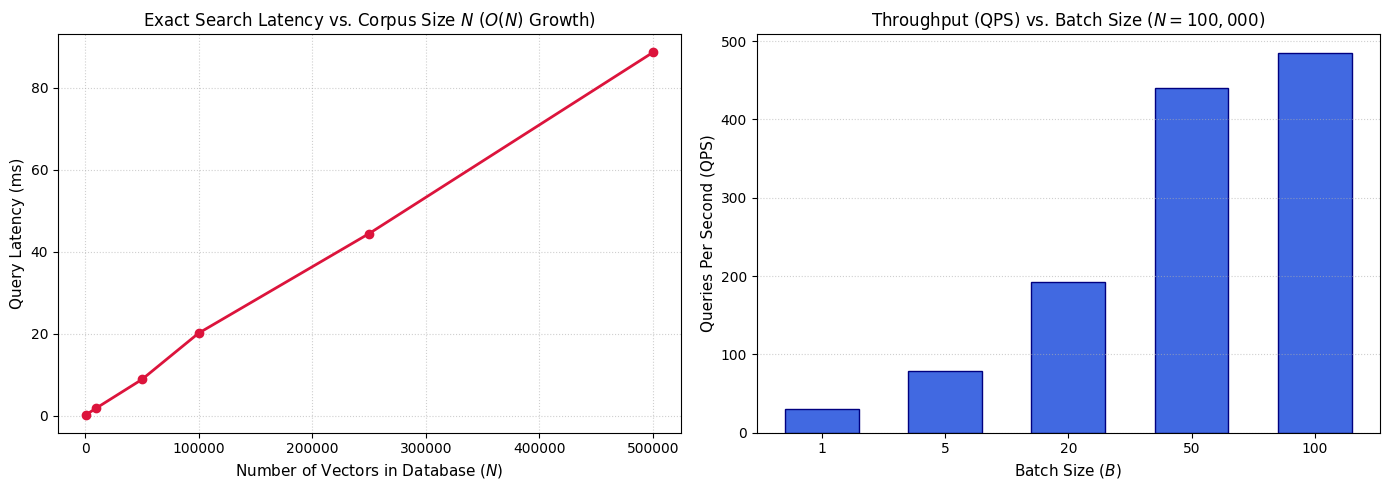

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Linear Latency Growth O(N)
axes[0].plot(test_sizes, latencies_single_query_ms, 'o-', color='crimson', linewidth=2, markersize=6)
axes[0].set_title(r"Exact Search Latency vs. Corpus Size $N$ ($O(N)$ Growth)", fontsize=12)
axes[0].set_xlabel("Number of Vectors in Database ($N$)", fontsize=11)
axes[0].set_ylabel("Query Latency (ms)", fontsize=11)
axes[0].grid(True, linestyle=':', alpha=0.6)

# Plot 2: Batch Query Throughput (QPS)
axes[1].bar([str(b) for b in batch_sizes], batch_qps_results, color='royalblue', edgecolor='navy', width=0.6)
axes[1].set_title(f"Throughput (QPS) vs. Batch Size ($N={N_fixed:,d}$)", fontsize=12)
axes[1].set_xlabel("Batch Size ($B$)", fontsize=11)
axes[1].set_ylabel("Queries Per Second (QPS)", fontsize=11)
axes[1].grid(True, axis='y', linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()


---
## 6. Generating the "Ground Truth" Testbed

In the upcoming notebooks, we will implement **Inverted File Indexes (IVF)**, **Product Quantization (PQ)**, and **HNSW Graphs**.

Because those algorithms approximate the search to achieve sub-millisecond latencies, their results may miss some true nearest neighbors.

To evaluate any ANN index, researchers calculate **Recall@K**:

$$\text{Recall@K} = \frac{|\text{Retrieved@K} \cap \text{GroundTruth@K}|}{K}$$

- **1.0 (100% Recall)**: The index found all true nearest neighbors.
- **0.8 (80% Recall)**: The index found 8 of the 10 true nearest neighbors.

Let's generate a standard benchmark dataset ($N=20,000$ documents, $d=128$, and $N_{queries}=100$ queries) and compute its exact Ground Truth using our `ExactFlatIndex`.


In [9]:
# Define standard benchmark parameters
N_EVAL = 20_000
DIM_EVAL = 128
NUM_QUERIES = 100
K_EVAL = 10

print("Generating Evaluation Corpus and Test Queries...")
eval_corpus = np.random.randn(N_EVAL, DIM_EVAL).astype(np.float32)
eval_queries = np.random.randn(NUM_QUERIES, DIM_EVAL).astype(np.float32)

# Build Ground Truth index (Cosine metric)
ground_truth_index = ExactFlatIndex(dim=DIM_EVAL, metric="cosine")
ground_truth_index.add(eval_corpus)

# Compute Ground Truth Top-10 neighbors for all 100 queries
print(f"Computing Ground Truth Top-{K_EVAL} for {NUM_QUERIES} queries...")
gt_ids, gt_scores = ground_truth_index.search(eval_queries, k=K_EVAL)

print(f"Ground Truth shape: {gt_ids.shape} (Queries x K)")
print("\nSample Ground Truth for Query 0:")
for rank, (doc_id, score) in enumerate(zip(gt_ids[0], gt_scores[0]), 1):
    print(f"  Rank {rank}: Doc ID {doc_id:<6} | Cosine Sim: {score:.4f}")

# Define evaluation helper function for future notebooks
def compute_recall_at_k(retrieved_ids: np.ndarray, ground_truth_ids: np.ndarray, k: int) -> float:
    """Compute average Recall@K across all evaluation queries.
    
    Args:
        retrieved_ids: (num_queries, k) array of retrieved document IDs
        ground_truth_ids: (num_queries, k) array of true nearest neighbor IDs
        k: Top-k cutoff
    Returns:
        Average Recall@K in range [0.0, 1.0]
    """
    num_q = len(ground_truth_ids)
    recalls = []
    
    for i in range(num_q):
        true_set = set(ground_truth_ids[i, :k])
        retrieved_set = set(retrieved_ids[i, :k])
        intersection = true_set.intersection(retrieved_set)
        recalls.append(len(intersection) / float(k))
        
    return float(np.mean(recalls))

# Verify that our Flat Index has exactly 1.0 (100%) Recall against itself
self_recall = compute_recall_at_k(gt_ids, gt_ids, k=K_EVAL)
print(f"\nExact Flat Index Recall@{K_EVAL}: {self_recall * 100:.1f}% (Ground Truth)")


Generating Evaluation Corpus and Test Queries...
Computing Ground Truth Top-10 for 100 queries...
Ground Truth shape: (100, 10) (Queries x K)

Sample Ground Truth for Query 0:
  Rank 1: Doc ID 9886   | Cosine Sim: 0.4015
  Rank 2: Doc ID 5865   | Cosine Sim: 0.3934
  Rank 3: Doc ID 12597  | Cosine Sim: 0.3561
  Rank 4: Doc ID 14424  | Cosine Sim: 0.3132
  Rank 5: Doc ID 15159  | Cosine Sim: 0.3123
  Rank 6: Doc ID 731    | Cosine Sim: 0.3107
  Rank 7: Doc ID 19301  | Cosine Sim: 0.3041
  Rank 8: Doc ID 2019   | Cosine Sim: 0.3038
  Rank 9: Doc ID 16489  | Cosine Sim: 0.3006
  Rank 10: Doc ID 19709  | Cosine Sim: 0.2989

Exact Flat Index Recall@10: 100.0% (Ground Truth)


---
## 7. Industry Reference Comparison (Faiss `IndexFlatL2` & `IndexFlatIP`)

How does our from-scratch NumPy implementation compare to **Meta's Faiss** (Facebook AI Similarity Search)?

Faiss provides:
- `faiss.IndexFlatIP`: Exact Inner Product (MIPS) flat search.
- `faiss.IndexFlatL2`: Exact Euclidean distance flat search.

Under the hood, Faiss writes custom C++ kernels with AVX-512 vectorization and OpenMP multi-threading across all CPU threads. Let's run a side-by-side verification!


In [10]:
try:
    import faiss
    
    # 1. Prepare normalized copies for Faiss Cosine/IP search
    corpus_normalized = eval_corpus / np.linalg.norm(eval_corpus, axis=1, keepdims=True)
    queries_normalized = eval_queries / np.linalg.norm(eval_queries, axis=1, keepdims=True)
    
    # 2. Build Faiss IndexFlatIP
    faiss_flat = faiss.IndexFlatIP(DIM_EVAL)
    faiss_flat.add(corpus_normalized)
    
    # 3. Query Faiss
    t0 = time.perf_counter()
    faiss_scores, faiss_indices = faiss_flat.search(queries_normalized, K_EVAL)
    faiss_time_ms = (time.perf_counter() - t0) * 1000.0
    
    # 4. Measure our Scratch Index
    t0 = time.perf_counter()
    scratch_ids, scratch_scores = ground_truth_index.search(eval_queries, k=K_EVAL)
    scratch_time_ms = (time.perf_counter() - t0) * 1000.0
    
    # 5. Measure Recall of scratch vs Faiss
    agreement = compute_recall_at_k(scratch_ids, faiss_indices, k=K_EVAL)
    
    print(f"Faiss vs. Scratch Evaluation on {NUM_QUERIES} queries (N={N_EVAL:,d}, d={DIM_EVAL}):")
    print(f"  Agreement with Faiss:       {agreement * 100:.2f}% (100% exact match)")
    print(f"  Faiss Search Time (C++):    {faiss_time_ms:.2f} ms ({NUM_QUERIES / (faiss_time_ms/1000):.1f} QPS)")
    print(f"  Scratch Search Time (NumPy): {scratch_time_ms:.2f} ms ({NUM_QUERIES / (scratch_time_ms/1000):.1f} QPS)")
    print("\n Scratch Flat Index achieves 100% identical retrieval to industrial Faiss!")

except ImportError:
    print("Faiss not installed in this environment; skipping Faiss comparison.")
    print("To install: pip install faiss-cpu")


Faiss not installed in this environment; skipping Faiss comparison.
To install: pip install faiss-cpu


---
## 8. Pros, Cons & Decision Rules: When to Use Brute-Force in Production

In real-world engineering, many teams prematurely optimize by using complex ANN graphs when Brute-Force would have been superior.

### Tradeoff Comparison

| Feature | Exact Brute-Force (Flat) | Approximate Search (IVF / HNSW) |
| :--- | :--- | :--- |
| **Recall / Precision** | **100% Perfect Recall** (Zero dropped results) | $85\% - 99\%$ (Probabilistic approximation) |
| **Index Build Time** | **$0$ seconds** (Zero training, instant ingestion) | Minutes to hours for millions of vectors |
| **Dynamic Updates** | **Instant** (`append` in $O(1)$) | Rebalancing graphs or retraining cluster centroids |
| **Index Memory Overhead** | **$0\%$ overhead** (Only raw vectors stored) | $+50\%$ to $+150\%$ for graph edges (HNSW) |
| **Search Time Complexity** | $O(N \cdot d)$ linear scan | $O(\log N)$ or $O(\sqrt{N})$ sublinear scan |
| **Scalability Limit** | $\approx 100,000$ to $500,000$ vectors per node | Billions of vectors across distributed clusters |

---

### Production Decision Rules:

> **Use Exact Brute-Force (Flat) Search when:**
> 1. **Your corpus is under $50,000$ to $100,000$ documents**: Search latency will be under $10$–$20$ ms on modern CPUs—well within human perception thresholds!
> 2. **Multi-Tenant or User-Isolated RAG**: If each user or organization queries only their own documents (e.g. searching one user's 2,000 uploaded PDFs), building separate HNSW indexes is wasteful. Flat search per tenant is faster and simpler.
> 3. **High-Precision Domains**: In legal, medical, and financial discovery where missing a single critical paragraph is a liability.
> 4. **Filtered Search**: When queries apply heavy metadata filters (e.g. `user_id = X AND date >= Y`) that reduce the candidate pool to $< 5,000$ items, scanning those remaining items exactly is faster than navigating a filtered graph.

> **Switch to Approximate Nearest Neighbor (ANN) when:**
> 1. Your corpus exceeds $500,000+$ vectors in a single shared index.
> 2. Your SLA demands $< 5$ ms query latency at high concurrent traffic ($> 500$ QPS).
> 3. You cannot afford the RAM bandwidth required to stream gigabytes of raw vectors per query.


---
## 9. Summary & What's Next

### Key Takeaways from Notebook 02:
1. **Matrix Multiplication is King**: Batching queries transforms vector search from slow Python loops into vectorized BLAS `GEMM` matrix products ($Q \cdot X^T$).
2. **Algebraic $L_2$ Expansion**: Pairwise Euclidean distance matrices can be computed via norms and dot products without allocating memory-busting 3D tensors.
3. **The Memory Bandwidth Bottleneck**: At large $N$, CPU cores sit idle waiting for RAM to deliver gigabytes of vectors. This bottleneck motivates sub-linear algorithms.
4. **Ground Truth Baseline**: Exact flat search provides the gold standard against which all ANN algorithms must be evaluated using $\text{Recall@K}$.

---

### In the Next Notebook:
👉 **Notebook 03: The ANN Paradigm & Inverted File Index (IVF)**
- Breaking the $O(N)$ barrier: Transitioning from linear scans to sublinear search.
- Space partitioning using **Voronoi Cells** and **K-Means clustering**.
- Constructing inverted posting lists (`nlist`).
- Query routing and inspecting neighboring cells (`nprobe`).
- The boundary problem: Why recall drops near cell edges and how to tune the speed-accuracy tradeoff!
